# 01 - Baseline CNN

Verify the assignment's baseline architecture and train it once as the reference point.

- **Architecture:** 4,961,124 parameters, exactly as specified.
- **Protocol:** 10 epochs, SGD lr=1e-2, batch 128, full 50k train / 10k test.
- **Artifact:** `task_a/runs/exp_000_baseline/` with `config.json`, `metrics.csv`,
  `curves.png`, and `model.pt`.

**How to run:** run top to bottom from `task_a/notebooks/`. A GPU is recommended.


## Setup - imports, device, and seeds

In [1]:
# Make `src` importable
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

# Project modules
from src.config import PROJECT_ROOT, DATA_DIR, RUNS_DIR, SEED, CIFAR100_MEAN, CIFAR100_STD
from src.models import baseline_cnn
from src.data import build_datasets, build_loaders
from src.engine import train_one_epoch, evaluate, fit
from src.utils import set_seed

import torch
from torchinfo import summary

# Train on GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '')

# Fix all RNG seeds BEFORE the model and the DataLoaders are created
set_seed(SEED)

cuda NVIDIA GeForce RTX 4060 Laptop GPU


## 1 - Verify the architecture and parameter count

In [2]:
# 2.1: verify the baseline architecture -- params must be 4,961,124, every Conv keeps 256x32x32
model = baseline_cnn().to(device)
summary(model, input_size=(1, 3, 32, 32))                                # per-layer params and output shapes
print("forward:", model(torch.randn(2, 3, 32, 32, device=device)).shape) # sanity check -> torch.Size([2, 100])
print("params: ", sum(p.numel() for p in model.parameters()))            # must equal 4961124

forward: torch.Size([2, 100])
params:  4961124


## 2 - Train for 10 epochs

In [3]:
# 2.4: baseline run -- exactly 10 epochs on the full train (50k) and test (10k) sets
train_loader, test_loader = build_loaders(batch_size=128)

# Fresh model with a new random init -- do NOT reuse the verification model from the cell above
model = baseline_cnn().to(device)
criterion = torch.nn.CrossEntropyLoss()                  # includes log_softmax -> the model must output raw logits
optimizer = torch.optim.SGD(model.parameters(), lr=1e-2) # plain SGD; optimizer choice is a stage-3 factor

# fit() = per epoch: train_one_epoch + evaluate; returns per-epoch metrics in `history`
history = fit(model, train_loader, test_loader,
              criterion, optimizer, epochs=10, device=device)

epoch  1/10 | train 4.597/0.015 | test 4.570/0.020 | 2054s
epoch  2/10 | train 4.421/0.032 | test 4.286/0.041 | 1940s
epoch  3/10 | train 4.254/0.044 | test 4.236/0.054 | 578s
epoch  4/10 | train 4.192/0.057 | test 4.175/0.063 | 147s
epoch  5/10 | train 4.112/0.071 | test 4.078/0.069 | 146s
epoch  6/10 | train 4.039/0.080 | test 3.997/0.083 | 147s
epoch  7/10 | train 3.962/0.090 | test 3.934/0.092 | 148s
epoch  8/10 | train 3.896/0.098 | test 3.887/0.109 | 147s
epoch  9/10 | train 3.846/0.108 | test 3.826/0.109 | 148s
epoch 10/10 | train 3.801/0.114 | test 3.787/0.118 | 147s


## 3 - Save the run

saved -> C:\Users\sigridwicks\Desktop\DL HW1\runs\exp_000_baseline
final test acc: 0.1182
epoch times  : [2054, 1940, 578, 147, 146, 147, 148, 147, 148, 147]


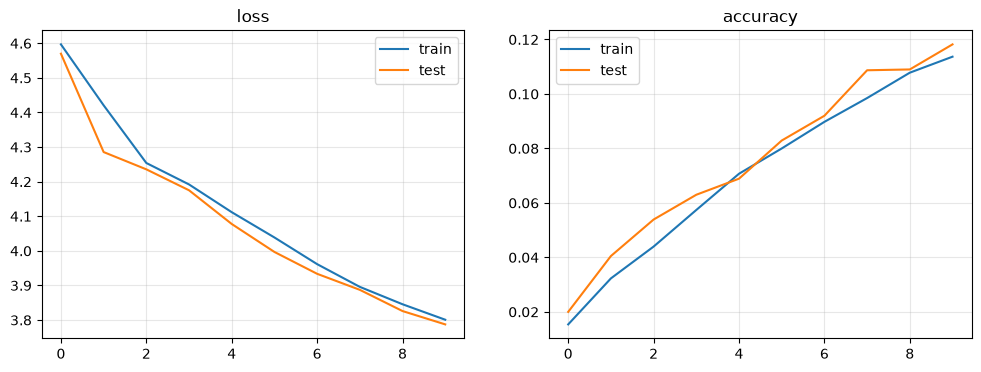

In [4]:

import json, csv
import matplotlib.pyplot as plt
from src.config import RUNS_DIR, SEED

run_dir = RUNS_DIR / "exp_000_baseline"
run_dir.mkdir(parents=True, exist_ok=True)

# 1) config.json: full configuration of this experiment
config = {"arch": "baseline", "epochs": 10, "lr": 0.01, "batch": 128,
        "optimizer": "SGD", "aug": "none", "seed": SEED}
(run_dir / "config.json").write_text(json.dumps(config, indent=2))

# 2) metrics.csv: per-epoch metrics
with open(run_dir / "metrics.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["epoch", "train_loss", "train_acc", "test_loss", "test_acc", "epoch_time"])
    for i in range(len(history["train_loss"])):
        w.writerow([i + 1, history["train_loss"][i], history["train_acc"][i],
                    history["test_loss"][i], history["test_acc"][i],
                    round(history["epoch_time"][i], 1)])

# 3) curves.png: loss and accuracy curves (train + test)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history["train_loss"], label="train"); ax1.plot(history["test_loss"], label="test")
ax1.set_title("loss"); ax1.legend(); ax1.grid(alpha=0.3)
ax2.plot(history["train_acc"], label="train"); ax2.plot(history["test_acc"], label="test")
ax2.set_title("accuracy"); ax2.legend(); ax2.grid(alpha=0.3)
fig.savefig(run_dir / "curves.png", dpi=150, bbox_inches="tight")

# 4) model.pt: weights
torch.save(model.state_dict(), run_dir / "model.pt")

print("saved ->", run_dir)
print("final test acc:", history["test_acc"][-1])
print("epoch times  :", [round(t) for t in history["epoch_time"]])
